#H M AHSAN HABIB KUSHAL
##CS 2203064
##DEPARTMENT OF COMPUTER SCIENCE AND ENGINEERING
###NATIONAL INSTITUTE OF TEXTILE ENGINEERING AND RESEARCH

###Importing Required Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

###Downloading The Indian Metropolitan area's housing prices dataset.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ruchi798/housing-prices-in-metropolitan-areas-of-india")

print("Path to dataset files:", path)



100%|██████████| 269k/269k [00:00<00:00, 76.7MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/ruchi798/housing-prices-in-metropolitan-areas-of-india/versions/4


In [ ]:
print(os.listdir(path))

['Bangalore.csv', 'Delhi.csv', 'Mumbai.csv', 'Chennai.csv', 'Kolkata.csv', 'Hyderabad.csv']


####Choosing Delhi for the Task.

In [ ]:
df = pd.read_csv(os.path.join(path, "Delhi.csv"))

In [ ]:
df

,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,...,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Refrigerator
0,10500000,1200,Sector 10 Dwarka,2,1,0,1,0,0,1,...,1,0,1,0,0,0,0,0,0,0
1,6000000,1000,Uttam Nagar,3,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,15000000,1350,Sarita Vihar,2,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2500000,435,Uttam Nagar,2,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,5800000,900,Dwarka Mor,3,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4993,2500000,540,Madhu Vihar,2,1,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
4994,3000000,540,Madhu Vihar,2,1,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
4995,2600000,415,Sector 26 Dwarka,1,1,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
4996,5500000,415,Sector 26 Dwarka,1,1,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9


##Feature Selection

In [ ]:
predictors = ['Area', 'No. of Bedrooms', 'Resale', 'MaintenanceStaff']
target = 'Price'

In [ ]:
df = df[predictors + [target]].copy()
df

,Area,No. of Bedrooms,Resale,MaintenanceStaff,Price
0,1200,2,1,0,10500000
1,1000,3,0,0,6000000
2,1350,2,1,0,15000000
3,435,2,0,0,2500000
4,900,3,0,0,5800000
...,...,...,...,...,...
4993,540,2,1,9,2500000
4994,540,2,1,9,3000000
4995,415,1,1,9,2600000
4996,415,1,1,9,5500000


##Exploratory Data Analysis (EDA)

In [ ]:
df.describe()

,Area,No. of Bedrooms,Resale,MaintenanceStaff,Price
count,4998.000000,4998.000000,4998.00000,4998.000000,4.998000e+03
mean,1277.343737,2.657863,0.80012,5.423770,1.588638e+07
std,915.217800,0.820605,0.39995,4.378355,4.612894e+07
min,200.000000,1.000000,0.00000,0.000000,2.000000e+06
25%,800.000000,2.000000,1.00000,0.000000,2.900000e+06
50%,1000.000000,3.000000,1.00000,9.000000,5.500000e+06
75%,1650.000000,3.000000,1.00000,9.000000,1.580000e+07
max,16000.000000,8.000000,1.00000,9.000000,8.546000e+08


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4998 entries, 0 to 4997
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Area              4998 non-null   int64
 1   No. of Bedrooms   4998 non-null   int64
 2   Resale            4998 non-null   int64
 3   MaintenanceStaff  4998 non-null   int64
 4   Price             4998 non-null   int64
dtypes: int64(5)
memory usage: 195.4 KB


In [ ]:
df.isnull().sum()

,0
Area,0
No. of Bedrooms,0
Resale,0
MaintenanceStaff,0
Price,0


######Hence, There is no Null value

##Train-Test Split (75 Training, and 25% Test data)

In [ ]:
np.random.seed(42)
shuffled_indices = np.random.permutation(len(df))
train_size = int(len(df)*0.75)
train_indices = shuffled_indices[:train_size]
test_indices = shuffled_indices[train_size:]
X_raw = df[predictors].values
y_raw = df[target].values

X_train_raw, y_train = X_raw[train_indices], y_raw[train_indices]
X_test_raw, y_test = X_raw[test_indices], y_raw[test_indices]

##Z-Score Normalization (Feature Scaling)

In [ ]:
def zscore_normalize(X):
  mu = np.mean(X,axis=0)
  sigma = np.std(X,axis=0)
  X_norm = (X - mu) / sigma
  return X_norm, mu, sigma

In [ ]:
# Scale Features ONLY
X_train, mu, sigma = zscore_normalize(X_train_raw)

#Multivariate Functions of Linear Regression

In [ ]:
def compute_cost_multi(X,y,w,b):
  m = X.shape[0]
  cost = np.sum(((X @ w +b)-y)**2)/(2*m)
  return cost

In [ ]:
def compute_gradient_multi(X,y,w,b):
  m,n = X.shape
  err = (X @ w + b) - y
  dj_dw = (1/m)*(X.T @ err)
  dj_db = (1/m) *np.sum(err)
  return dj_dw, dj_db

In [ ]:
def gradient_descent_multi(X,y,w_in,b_in,alpha,num_iters):
  w = w_in
  b = b_in
  J_history = []

  for i in range(num_iters):
    dj_dw , dj_db = compute_gradient_multi(X,y,w,b)
    w = w - alpha *dj_dw
    b = b - alpha *dj_db
    J_history.append(compute_cost_multi(X,y,w,b))
  return w, b, J_history

#Model Training

In [ ]:
initial_w = np.zeros(X_train.shape[1])
initial_b = 0.01
alpha = 0.01
iterations = 500

final_w_multi, final_b_multi, J_history_multi = gradient_descent_multi(X_train, y_train, initial_w, initial_b, alpha, iterations)

print(f"\nTrained Weights (W) are: {final_w_multi}")


Trained Weights (W) are: [18669000.20300124 -2604948.96376579 -2672085.68941368  3525579.86345751]


In [ ]:
print(f"Trained Bias (B): {final_b_multi}")

Trained Bias (B): 15595487.11571235


<h1>Evaluation</h1>

##Final Training Cost

In [ ]:
test_cost = compute_cost_multi(X_test, y_test, final_w_multi, final_b_multi)
print(f"Final Test Set Cost (MSE/2): {test_cost:.4f}")

Final Test Set Cost (MSE/2): 919575566568852.1250


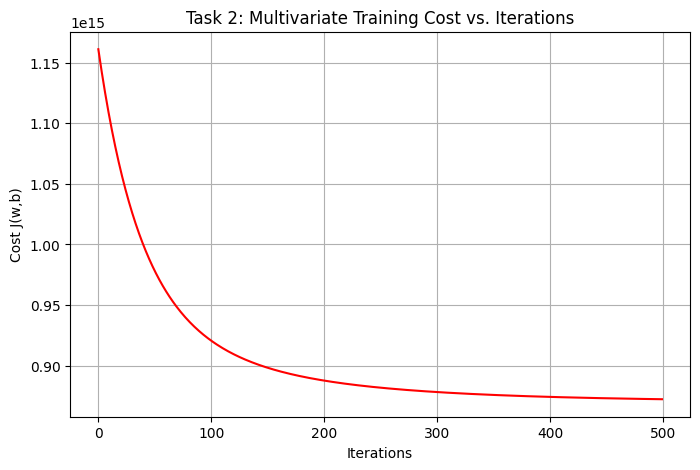

In [ ]:
# 8. Plot Cost vs Iterations
plt.figure(figsize=(8, 5))
plt.plot(range(iterations), J_history_multi, color='red')
plt.xlabel('Iterations')
plt.ylabel('Cost J(w,b)')
plt.title('Task 2: Multivariate Training Cost vs. Iterations')
plt.grid(True)
plt.show()

#Denormalization

In [ ]:
w_raw = final_w_multi / sigma
b_raw = final_b_multi - np.sum((final_w_multi * mu) / sigma)

print("--- Trained Parameters (Scaled Space) ---")
print(f"final_w_multi: {final_w_multi}")
print(f"final_b_multi: {final_b_multi:.2f}\n")

print("--- Denormalized Parameters (Raw Space) ---")
for feat, w_val in zip(predictors, w_raw):
    print(f"Weight for {feat} (w_raw): {w_val:.4f}")
print(f"Intercept / Bias (b_raw): {b_raw:.4f}\n")

--- Trained Parameters (Scaled Space) ---
final_w_multi: [18669000.20300124 -2604948.96376579 -2672085.68941368  3525579.86345751]
final_b_multi: 15595487.12

--- Denormalized Parameters (Raw Space) ---
Weight for Area (w_raw): 21537.4519
Weight for No. of Bedrooms (w_raw): -3167492.0705
Weight for Resale (w_raw): -6754307.0888
Weight for MaintenanceStaff (w_raw): 802909.5338
Intercept / Bias (b_raw): -2356177.8437



#Predictions on Test Set & Model Evaluation

In [ ]:
y_test_pred = X_test_raw @ final_w_multi + final_b_multi
test_cost = compute_cost_multi(X_test_raw, y_test, final_w_multi, final_b_multi)
print(f"\nFinal Test Set Cost J(w,b): {test_cost:.4f}")
comparison_df = pd.DataFrame({
    'Actual Price': y_test[:10],
    'Predicted Price': y_test_pred[:10],
    'Difference (Error)': y_test[:10] - y_test_pred[:10]})

comparison_df


Final Test Set Cost J(w,b): 475538717302841802752.0000


,Actual Price,Predicted Price,Difference (Error)
0,12500000,2.339176e+10,-2.337926e+10
1,2600000,3.086196e+10,-3.085936e+10
2,3300000,1.354592e+11,-1.354559e+11
3,6700000,4.670673e+10,-4.670003e+10
4,35000000,3.028322e+10,-3.024822e+10
5,7500000,2.054361e+10,-2.053611e+10
6,2700000,3.364364e+10,-3.364094e+10
7,15000000,2.521086e+10,-2.519586e+10
8,19500000,3.547360e+10,-3.545410e+10
9,35000000,3.360670e+10,-3.357170e+10


#Multivariate Regression plot with Actual vs. Predicted Prices Scatter plot

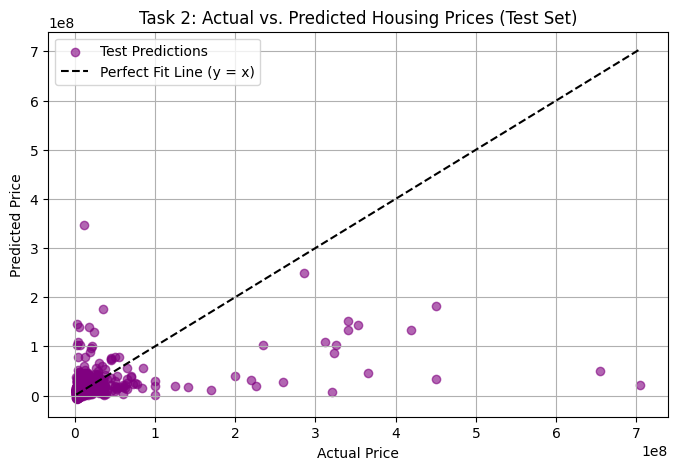

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_test_pred, color='purple', alpha=0.6, label='Test Predictions')
# Plot ideal 1:1 prediction line
ideal_line = np.linspace(min(y_test), max(y_test), 100)
plt.plot(ideal_line, ideal_line, color='black', linestyle='--', label='Perfect Fit Line (y = x)')

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Task 2: Actual vs. Predicted Housing Prices (Test Set)')
plt.legend()
plt.grid(True)
plt.show()

## Robust Pipeline: Log Transformation for Target Variable

The previous linear regression model struggled due to the highly skewed distribution of `Price` (our target variable) and the presence of extreme outliers. These factors violate the assumptions of linear regression, leading to poor model performance.

To address this, we will apply a log transformation to the `Price` variable. This technique:
- **Compresses large values:** Reduces the impact of outliers.
- **Normalizes the distribution:** Makes the target variable's distribution more symmetrical, closer to a normal distribution, which is ideal for linear regression.

After training the model on the log-transformed prices, we will use the inverse operation (exponentiation, `np.exp()`) to convert our predictions back to the original price scale for interpretation and evaluation.

In [ ]:
# Apply log transformation to the target variable
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

# Scale X_test using the mu and sigma from X_train_raw
X_test = (X_test_raw - mu) / sigma

print(f"Original y_train mean: {y_train.mean():.2f}")
print(f"Log-transformed y_train mean: {y_train_log.mean():.2f}")
print(f"Original y_test mean: {y_test.mean():.2f}")
print(f"Log-transformed y_test mean: {y_test_log.mean():.2f}")

Original y_train mean: 15698634.73
Log-transformed y_train mean: 15.78
Original y_test mean: 16449330.39
Log-transformed y_test mean: 15.82


### Model Training with Log-Transformed Target

Now, we will retrain our multivariate linear regression model using the scaled features (`X_train`) and the log-transformed target variable (`y_train_log`). This should result in a more stable and accurate model.

In [ ]:
# Re-initialize parameters for training with log-transformed target
initial_w_log = np.zeros(X_train.shape[1])
initial_b_log = 0.01
alpha = 0.01
iterations = 1200

# Train the model
final_w_log, final_b_log, J_history_log = gradient_descent_multi(X_train, y_train_log, initial_w_log, initial_b_log, alpha, iterations)

print(f"\nTrained Weights (W) for log-transformed target are: {final_w_log}")
print(f"Trained Bias (B) for log-transformed target: {final_b_log}")


Trained Weights (W) for log-transformed target are: [ 0.50753664  0.04072416  0.12492133 -0.10429268]
Trained Bias (B) for log-transformed target: 15.7823739532079


### Model Evaluation and Denormalization

After training, we evaluate the model on the test set. Since the model was trained on log-transformed prices, our predictions (`y_test_pred_log`) will also be in the log scale. We must apply `np.exp()` to these predictions to convert them back to the original price scale (`y_test_pred`) for meaningful comparison with the actual prices.

In [ ]:
# Predict on the scaled X_test data (predictions are in log scale)
y_test_pred_log = X_test @ final_w_log + final_b_log

# Denormalize predictions back to original price scale
y_test_pred = np.exp(y_test_pred_log)

# Calculate the cost on the log-transformed test set
test_cost_log = compute_cost_multi(X_test, y_test_log, final_w_log, final_b_log)
print(f"\nFinal Test Set Cost (MSE/2) on log-transformed prices: {test_cost_log:.4f}")

# Create a comparison DataFrame for denormalized predictions
comparison_df_robust = pd.DataFrame({
    'Actual Price': y_test[:10],
    'Predicted Price': y_test_pred[:10],
    'Difference (Error)': y_test[:10] - y_test_pred[:10]
})

print("\nTop 10 Actual vs. Denormalized Predicted Prices:")
display(comparison_df_robust)


Final Test Set Cost (MSE/2) on log-transformed prices: 0.4025

Top 10 Actual vs. Denormalized Predicted Prices:


,Actual Price,Predicted Price,Difference (Error)
0,12500000,6.983072e+06,5.516928e+06
1,2600000,8.399547e+06,-5.799547e+06
2,3300000,1.889773e+08,-1.856773e+08
3,6700000,1.524605e+07,-8.546046e+06
4,35000000,8.248461e+06,2.675154e+07
5,7500000,7.533200e+06,-3.320016e+04
6,2700000,9.165258e+06,-6.465258e+06
7,15000000,8.720701e+06,6.279299e+06
8,19500000,1.328681e+07,6.213187e+06
9,35000000,1.253118e+07,2.246882e+07


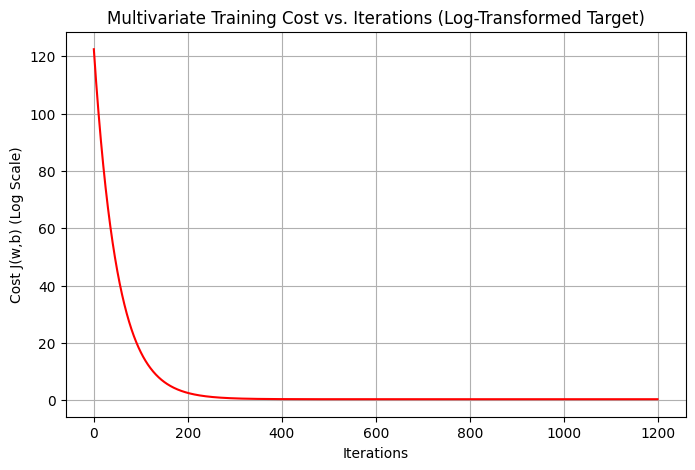

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(iterations), J_history_log, color='red')
plt.xlabel('Iterations')
plt.ylabel('Cost J(w,b) (Log Scale)')
plt.title('Multivariate Training Cost vs. Iterations (Log-Transformed Target)')
plt.grid(True)
plt.show()

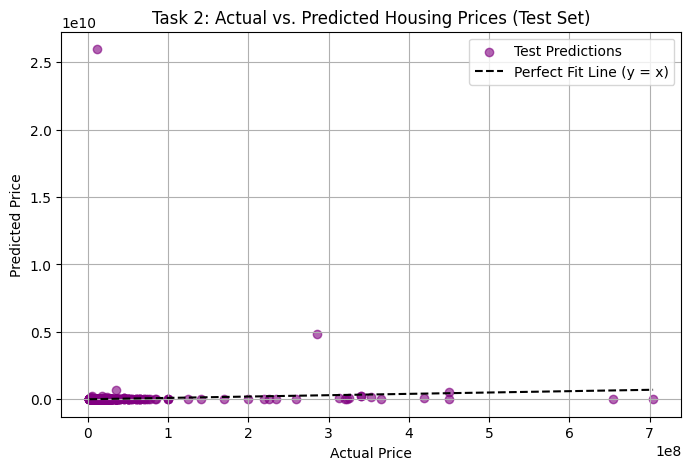

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_test_pred, color='purple', alpha=0.6, label='Test Predictions')
ideal_line = np.linspace(min(y_test), max(y_test), 100)
plt.plot(ideal_line, ideal_line, color='black', linestyle='--', label='Perfect Fit Line (y = x)')

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Task 2: Actual vs. Predicted Housing Prices (Test Set)')
plt.legend()
plt.grid(True)
plt.show()